# Dark.ModelBreakers · Milestone 3
**Saved-image evasion, score capping, and robustness under image transformations**  
FIT5230 · LIU JUNPENG and WANG YUNJIE · course version frozen 18 October 2026

This notebook reproduces the **course implementation frozen before the later LAO architecture work**.
It runs a small, fixed example end to end and separately audits the archived 100-image course results.
**Verified execution, 21 October 2026:** all **23 code cells** completed in order in one fresh Google Colab session on **NVIDIA L4 / CUDA / FP32** (run `20261021T085259Z_87a98a`). The user started Run all; the saved notebook and exported results were subsequently independently audited. Both the original course workflow and the SFA extension ran in this cloud session.

**Updated 21 October: PreDecodeGuard blind review and reconciliation are complete: seven submitted attacks succeeded and three controls stayed flagged.**
Liu Junpeng's SFA is now an independent pixel-space extension using the team's actual frozen detectors, with its own matched PGD and spectrum-only controls (section 8).
**Output provenance:** all displayed code-cell outputs are from this 21 October cloud run. The section explicitly labelled “Archived course results” still reads the historical 100-image dataset; it is not a new 100-image inference run. Earlier 18 October cloud and 21 October local MPS versions remain archived separately. No detector was retrained.
Later LAO v1/v2/v3 architecture experiments and paper extensions are outside this notebook.

## Run instructions
1. Select a GPU runtime. This notebook has completed on **NVIDIA L4 (22 GiB, CUDA, FP32)** with the default 3-image workload. The upstream recommendation is at least 32 GB, so A100 offers more headroom. A 16 GB T4 has not been verified.
2. Use the prepared Google Drive folder `FIT5230_M3` (or change `RESOURCE_FOLDER` below). It contains `m3_course_bundle.zip`, the new `m3_sfa_addon.zip`, and a `weights/` folder with five author checkpoints and the LPIPS VGG cache. Alternatively, upload the delivered `m3_weights.zip` into the same folder.
3. Run all cells. Authorize your own Drive mount when prompted. The attack model is fetched from a pinned HF revision, then verified against file hashes.
4. Keep the cell outputs when saving. The last cell also saves a ZIP of new images, logs, metrics, and figures back to Drive.

Default: **3 fixed generated inputs × 7 methods**, 10 real development images for CAP calibration, and 100 separate real test images for FPR.
Set `N_IMAGES=100` to rerun the course-sized attack evaluation. The small default proves execution, not statistical generalization.
No model is retrained. Fresh output folders prevent accidental reuse of archived results.
SFA default: 10 fixed generated test inputs × 3 methods, a 10-image real/dev reference, and 100 real/test inputs. Set `SFA_N_IMAGES=100` in section 8 for the full course set. Its strict saved-image budget applies only to those three pixel-space methods.

## 1. Question and experimental design
Our M2 work extended StealthDiffusion's PGD → latent optimization → Control-VAE pipeline with ensemble surrogates and loss-path options.
M3 asks what actually affects the **saved artifact**, whether very high fixed-threshold evasion hides score overshoot, and whether evasion survives JPEG/resizing.

| Configuration | What changes | What it tests |
|---|---|---|
| A5 | Archived released-pipeline baseline | Reference behavior |
| A2 | Zero latent-optimization iterations | Contribution of the existing latent loop |
| X2 | Feed the clean image into the Control-VAE control path | Dependence on the control image |
| X4 | Clean inversion, clean control, zero latent iterations | Reconstruction-only control |
| ENS | Optimize E/R/D instead of E alone | Within-collection surrogate transfer |
| CAPB_ENS | Capped PGD + crossing-step bisection, E/R/D | Overshoot and perceptual distortion |
| EOT_ENS | Average PGD loss over identity/JPEG75/resize0.5 | Transformation robustness |

**CAPB and EOT are separate experiments. No CAP+EOT combination is claimed.**
E=EfficientNet-B0, R=ResNet-50, D=DeiT, S=Swin. The supplied file is named `swin-t.pth`, but the wrapper instantiates Swin-base.
S is excluded from the optimization loss. It is from the same supplied detector collection, so this is limited transfer evidence.

The course data consist of 100 fixed SD1.5-generated test images and 100 Imagenette real test images, with separate 10-image dev splits.
The attack uses the archived SD2.1 backbone. Generation is already complete: manifests preserve prompts/seeds/model provenance.
CAP calibration reads **real/dev only**. Test outputs are evaluated after saving and reloading PNGs in a separate process.
This is reproduction of the existing course test set, not a newly held-out validation study.

Conditional ASR = originally detected AI images that become real / originally detected AI images, under the **same** transform.
Always show the numerator/denominator and real-image FPR. The decoder changes the image beyond the PGD stage;
this course pipeline does **not** impose a common final-image L∞ bound across all methods.

In [1]:
# Configuration: change only these inputs for another supported runtime.
import os, sys, json, hashlib, shutil, subprocess, zipfile, uuid, datetime
from pathlib import Path
from IPython.display import display, Markdown
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
RESOURCE_FOLDER = "/content/drive/MyDrive/FIT5230_M3"
N_IMAGES = 3
METHODS = ("A5", "A2", "X2", "X4", "ENS", "CAPB_ENS", "EOT_ENS")
CONDITIONS = ("none", "jpeg75", "resize05")
RUN_ID = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
RESOURCE = Path(RESOURCE_FOLDER) if IN_COLAB else Path(os.environ.get("M3_RESOURCE_DIR", ".")).resolve()
WORK = (Path("/content/m3_runs") if IN_COLAB else Path(os.environ.get("M3_WORK_ROOT", "m3_runs"))) / RUN_ID
WORK.mkdir(parents=True, exist_ok=False)
print("Execution mode:", "Colab CUDA" if IN_COLAB else "Local Jupyter; hardware is recorded below")
print("Run ID:", RUN_ID, "| generated inputs per method:", N_IMAGES)
print("Methods:", ", ".join(METHODS))

Execution mode: Colab CUDA
Run ID: 20261021T085259Z_87a98a | generated inputs per method: 3
Methods: A5, A2, X2, X4, ENS, CAPB_ENS, EOT_ENS


In [2]:
# Verify the delivered ZIP before loading its code. Never extract arbitrary paths.
EXPECTED_BUNDLE_SHA256 = "dc6d42d25d610a3a3a3c5d0f9faebab30fb5af5ba4976a974d7e9413078bf63a"
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()
def extract_checked(archive, destination):
    destination = Path(destination).resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for entry in z.infolist():
            target = destination / entry.filename
            assert not Path(entry.filename).is_absolute() and ".." not in Path(entry.filename).parts
            assert target.resolve().is_relative_to(destination)
            assert (entry.external_attr >> 16) & 0o170000 != 0o120000, "ZIP symlinks are unsupported"
        z.extractall(destination)
archive = RESOURCE / "m3_course_bundle.zip"
assert archive.is_file(), "Place m3_course_bundle.zip in RESOURCE_FOLDER first."
assert file_sha256(archive) == EXPECTED_BUNDLE_SHA256, "Course bundle changed; use the matching notebook and ZIP."
BUNDLE = WORK / "bundle"
extract_checked(archive, BUNDLE)
sys.path.insert(0, str(BUNDLE))
sys.dont_write_bytecode = True
import m3_runtime as runtime
import m3_reporting as report
bundle_check = runtime.verify_bundle(BUNDLE)
print("Verified source snapshot:", bundle_check["source_snapshot"])
print("Verified files:", bundle_check["verified_files"], "| image counts:", bundle_check["image_counts"])
print("Dev/test file-hash overlap:", bundle_check["dev_test_hash_overlap"])

Mounted at /content/drive
Verified source snapshot: before_lao_architecture_optimization_20261018_145942
Verified files: 244 | image counts: {'gen/dev': 10, 'gen/test': 100, 'real/dev': 10, 'real/test': 100}
Dev/test file-hash overlap: 0


In [3]:
# A separate Python 3.10 process isolates the archived ML stack from Colab's kernel.
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv==0.9.4"], check=True)
    UV = shutil.which("uv")
    PYTHON = "/content/m3_sdenv/bin/python"
    if not Path(PYTHON).exists():
        subprocess.run([UV, "venv", "--python", "3.10", "/content/m3_sdenv"], check=True)
    subprocess.run([UV, "pip", "install", "--python", PYTHON, "torch==2.2.2", "torchvision==0.17.2",
                    "--index-url", "https://download.pytorch.org/whl/cu121"], check=True)
    PACKAGES = ["setuptools==80.9.0", "numpy==1.26.4", "diffusers==0.12.1", "huggingface_hub==0.23.4",
                "transformers==4.30.2", "accelerate==0.20.3", "timm==0.6.12", "efficientnet-pytorch==0.7.1",
                "torchattacks==3.5.1", "lossers==0.0.9", "eagerpy==0.30.0", "natsort==8.4.0",
                "tensorboardX==2.6.2.2", "scipy==1.11.4", "scikit-learn==1.3.2",
                "opencv-python-headless==4.10.0.84", "Pillow==10.4.0", "tqdm==4.66.1", "safetensors==0.4.3"]
    subprocess.run([UV, "pip", "install", "--python", PYTHON, *PACKAGES], check=True)
else:
    PYTHON = os.environ.get("M3_PYTHON", sys.executable)
env_info = runtime.environment_info(PYTHON, "cuda" if IN_COLAB else "auto")
DEVICE = env_info["device"]
assert DEVICE in ("cuda", "mps"), "Use a GPU runtime for the full archived diffusion pipeline."
display(env_info)
if IN_COLAB and env_info["cuda_total_memory_bytes"] < 30 * 1024**3:
    print("Memory advisory: upstream recommends at least 32 GB. Attempting the unchanged pipeline on this GPU; if CUDA runs out of memory, use A100 and restart Run all.")
dependency_probe = "import importlib.metadata as m,json; print(json.dumps({p:m.version(p) for p in ['torch','torchvision','numpy','diffusers','transformers','timm','lossers','huggingface_hub']},indent=2))"
dependencies = json.loads(subprocess.check_output([PYTHON, "-B", "-c", dependency_probe], text=True))
assert dependencies["torch"].split("+")[0] == "2.2.2" and dependencies["diffusers"] == "0.12.1"
assert dependencies["lossers"] == "0.0.9", "Use the calibrated LPIPS dependency version."
print(json.dumps(dependencies, indent=2))
(WORK / "environment.json").write_text(json.dumps({"runtime":env_info,"packages":dependencies}, indent=2))

{'python': '/content/m3_sdenv/bin/python',
 'python_version': '3.10.19',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'torch': '2.2.2+cu121',
 'cuda_available': True,
 'cuda_device_name': 'NVIDIA L4',
 'cuda_total_memory_bytes': 23659151360,
 'mps_available': False,
 'device': 'cuda'}

Memory advisory: upstream recommends at least 32 GB. Attempting the unchanged pipeline on this GPU; if CUDA runs out of memory, use A100 and restart Run all.
{
  "torch": "2.2.2+cu121",
  "torchvision": "0.17.2+cu121",
  "numpy": "1.26.4",
  "diffusers": "0.12.1",
  "transformers": "4.30.2",
  "timm": "0.6.12",
  "lossers": "0.0.9",
  "huggingface_hub": "0.23.4"
}


585

In [4]:
# Load author checkpoints/cache and pin the diffusion model. All bytes are verified.
resources = json.loads((BUNDLE / "resources.json").read_text())
if IN_COLAB:
    weights_archive = RESOURCE / "m3_weights.zip"
    WEIGHTS = WORK / "weights"
    if weights_archive.is_file():
        extract_checked(weights_archive, WEIGHTS)
    else:
        assert (RESOURCE/"weights"/"checkpoints").is_dir(), "Provide weights/ or m3_weights.zip in RESOURCE_FOLDER."
        # Copy six files once from Drive to local disk; avoid model I/O over Drive.
        for item in resources["weights"]:
            source = RESOURCE/"weights"/item["path"]
            target = WEIGHTS/item["path"]
            target.parent.mkdir(parents=True,exist_ok=True)
            shutil.copyfile(source,target)
    CHECKPOINT_DIR, LPIPS_CACHE = WEIGHTS / "checkpoints", WEIGHTS / ".cache"
    spec = resources["sd_model"]
    download_code = (
        "from huggingface_hub import snapshot_download; import json; "
        "p=snapshot_download(repo_id=" + repr(spec["repo_id"]) + ",revision=" + repr(spec["revision"]) +
        ",allow_patterns=" + repr([r["path"] for r in spec["files"]]) + "); print('MODEL_PATH='+p)"
    )
    dl = subprocess.run([PYTHON, "-B", "-c", download_code], check=True, text=True, stdout=subprocess.PIPE)
    print(dl.stdout)
    MODEL_DIR = Path([s.split("=",1)[1] for s in dl.stdout.splitlines() if s.startswith("MODEL_PATH=")][-1])
else:
    CHECKPOINT_DIR = Path(os.environ["M3_CHECKPOINT_DIR"])
    LPIPS_CACHE = Path(os.environ["M3_LPIPS_CACHE"])
    MODEL_DIR = Path(os.environ["M3_MODEL_DIR"])
for item in resources["sd_model"]["files"]:
    p = MODEL_DIR / item["path"]
    assert p.is_file() and p.stat().st_size == item["bytes"] and file_sha256(p) == item["sha256"], item["path"]
RUNTIME = runtime.prepare_runtime(BUNDLE, WORK / "runtime", CHECKPOINT_DIR, LPIPS_CACHE)
DATA = BUNDLE / "data"
OUT = WORK / "new_execution"
print("Verified five author checkpoints, LPIPS VGG, and", len(resources["sd_model"]["files"]), "diffusion model files.")
print("Model revision:", resources["sd_model"]["revision"])
print("Prepared fresh runtime. No attack has been run by the setup cells.")

MODEL_PATH=/root/.cache/huggingface/hub/models--Manojb--stable-diffusion-2-1-base/snapshots/0094d483a120f3f33dafbd187ea4aa60d10de75c

Verified five author checkpoints, LPIPS VGG, and 13 diffusion model files.
Model revision: 0094d483a120f3f33dafbd187ea4aa60d10de75c
Prepared fresh runtime. No attack has been run by the setup cells.


## 2. Input audit and source visibility
Development/test filenames restart at `0000`, so split names and image contents matter, not the basename alone.
We check both file hashes and decoded RGB content, plus distinct generator seeds and real-image provenance.
Methods and parameters are fixed before this reproduction. We do not select successful examples after execution.

PASS: decoded-RGB, generator-seed, and real-source dev/test separation.


,image_id,prompt,seed,model,steps,guidance,source512
0,0000,a photo of a tench,5230010,stable-diffusion-v1-5/stable-diffusion-v1-5,30,7.5,gen512/0010.png
1,0001,a photo of a English springer spaniel,5230011,stable-diffusion-v1-5/stable-diffusion-v1-5,30,7.5,gen512/0011.png
2,0002,a photo of a cassette player,5230012,stable-diffusion-v1-5/stable-diffusion-v1-5,30,7.5,gen512/0012.png


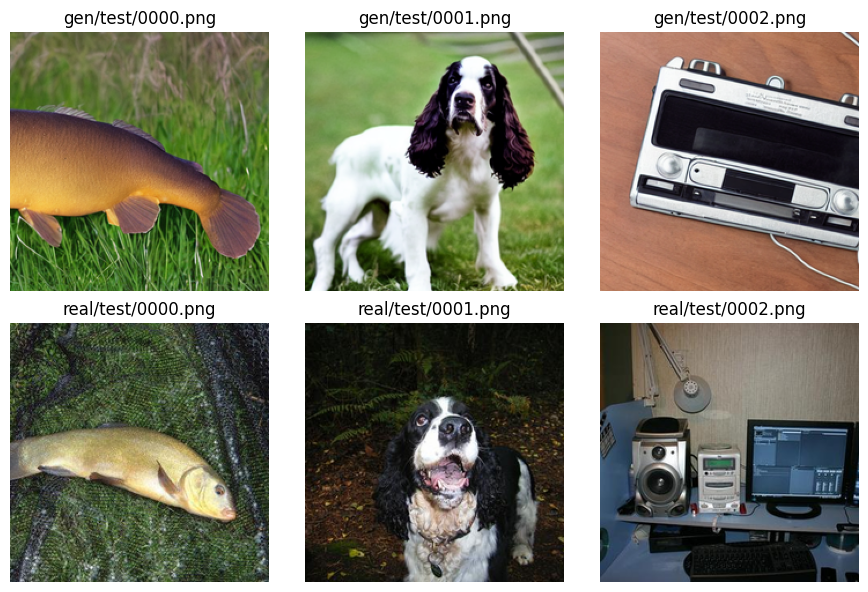

Core source SHA-256: d4c1c1b81a726f366461bfeff9f451a5776c227b1c4734b624ba317b0eb9efcb
Only portability changes: # Course snapshot and portability

Source snapshot: `before_lao_architecture_optimization_20261018_145942`. Original files were checked against its SHA-256 manifest.

The only attack-source edit is in `src/other_attacks.py`: use visible GPU 0; construct EfficientNet and Swin without downloading generic ImageNet initialization. The supplied forensic checkpoint is still loaded with strict=True (PyTorch default). No attack objective, gradient loop, detector checkpoint, or evaluation rule is changed.

The portable runner creates fresh directories and calls the archived commands explicitly. It never imports the later m3_lao_support or LAO v1/v2/v3 experiments.

Image manifests identify the fixed SD1.5-generated inputs and Imagenette real inputs. The 512-pixel generation cache is not needed for this saved-224-pixel-input reproduction.

Historical CSVs are archived measurements, not

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
def rgb_hashes(kind, split):
    result = set()
    for p in (DATA / kind / split).glob("*.png"):
        with Image.open(p) as im:
            result.add(hashlib.sha256(im.convert("RGB").tobytes()).hexdigest())
    return result
for kind in ("gen", "real"):
    assert not (rgb_hashes(kind, "dev") & rgb_hashes(kind, "test")), f"{kind} pixel overlap"
manifests = {(k,s):pd.read_csv(DATA/k/s/"manifest.csv", dtype={"image_id":str})
             for k in ("gen","real") for s in ("dev","test")}
assert set(manifests["gen","dev"].seed).isdisjoint(set(manifests["gen","test"].seed))
assert set(manifests["real","dev"].source).isdisjoint(set(manifests["real","test"].source))
print("PASS: decoded-RGB, generator-seed, and real-source dev/test separation.")
SHOW_N = min(N_IMAGES, 3)
display(manifests["gen","test"].head(SHOW_N))
fig, axes = plt.subplots(2, SHOW_N, figsize=(3*SHOW_N,6), squeeze=False)
for row,kind in enumerate(("gen","real")):
    for col,p in enumerate(sorted((DATA/kind/"test").glob("*.png"))[:SHOW_N]):
        axes[row,col].imshow(Image.open(p)); axes[row,col].axis("off")
        axes[row,col].set_title(f"{kind}/test/{p.name}")
fig.tight_layout(); plt.show()
# The complete readable implementation is in the verified bundle, not encoded text.
print("Core source SHA-256:", file_sha256(BUNDLE / "src" / "m2_stealth.py"))
print("Only portability changes:", (BUNDLE/"PORTABILITY.md").read_text())

## 3. Fresh end-to-end execution
Each cell below starts a clean model process and actually computes the attack.
Every final image is saved as PNG along with its original, intermediate stages, records, configuration, and hashes.
The fresh output directory cannot be reused accidentally. Changing to 100 images reruns every method on the same full test set.

In [6]:
# A5: real model execution, not an archived log replay.
result_A5 = runtime.run_method(RUNTIME, DATA, OUT, "A5",
                                  python=PYTHON, device=DEVICE, model_dir=MODEL_DIR, max_images=N_IMAGES)
print(json.dumps(result_A5, indent=2))

You are offline and the cache for model files in Transformers v4.22.0 has been updated while your local cache seems to be the one of a previous version. It is very likely that all your calls to any `from_pretrained()` method will fail. Remove the offline mode and enable internet connection to have your cache be updated automatically, then you can go back to offline mode.

0it [00:00, ?it/s]
0it [00:00, ?it/s]
[m2_device] using device: cuda
[m2] loading Stable Diffusion from /root/.cache/huggingface/hub/models--Manojb--stable-diffusion-2-1-base/snapshots/0094d483a120f3f33dafbd187ea4aa60d10de75c
[m2] loading detectors ['D', 'E', 'R', 'S']

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 16.03it/s]
[m2] 0000 8.8s psnr=34.50 ssim=0.925 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.37it/s]
[m2] 0001 7.7s psnr=34.97 ssim=0.917 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:AI S:real

DDIM_inverse: 100%|██████████| 1

In [7]:
# A2: real model execution, not an archived log replay.
result_A2 = runtime.run_method(RUNTIME, DATA, OUT, "A2",
                                  python=PYTHON, device=DEVICE, model_dir=MODEL_DIR, max_images=N_IMAGES)
print(json.dumps(result_A2, indent=2))

[m2_device] using device: cuda
[m2] loading Stable Diffusion from /root/.cache/huggingface/hub/models--Manojb--stable-diffusion-2-1-base/snapshots/0094d483a120f3f33dafbd187ea4aa60d10de75c
[m2] loading detectors ['D', 'E', 'R', 'S']

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 16.02it/s]
[m2] 0000 3.6s psnr=34.62 ssim=0.926 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.28it/s]
[m2] 0001 2.6s psnr=35.11 ssim=0.920 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.32it/s]
[m2] 0002 2.6s psnr=34.76 ssim=0.898 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:AI S:real
[m2] done. outputs in /content/m3_runs/20261021T085259Z_87a98a/new_execution/A2
{
  "method": "A2",
  "output_dir": "/content/m3_runs/20261021T085259Z_87a98a/new_execution/A2",
  "n_images": 3,
  "saved_png_count": 15,
  "stdout_log": "/content/m3_runs/20261021T085259Z_87a98a/new_exec

In [8]:
# X2: real model execution, not an archived log replay.
result_X2 = runtime.run_method(RUNTIME, DATA, OUT, "X2",
                                  python=PYTHON, device=DEVICE, model_dir=MODEL_DIR, max_images=N_IMAGES)
print(json.dumps(result_X2, indent=2))

[m2_device] using device: cuda
[m2] loading Stable Diffusion from /root/.cache/huggingface/hub/models--Manojb--stable-diffusion-2-1-base/snapshots/0094d483a120f3f33dafbd187ea4aa60d10de75c
[m2] loading detectors ['D', 'E', 'R', 'S']

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 16.03it/s]
[m2] 0000 8.4s psnr=39.41 ssim=0.993 pgd_steps[pgd1:10] final-> E:AI R:AI D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.32it/s]
[m2] 0001 7.3s psnr=41.13 ssim=0.993 pgd_steps[pgd1:10] final-> E:AI R:AI D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.32it/s]
[m2] 0002 7.4s psnr=40.24 ssim=0.996 pgd_steps[pgd1:10] final-> E:AI R:AI D:AI S:real
[m2] done. outputs in /content/m3_runs/20261021T085259Z_87a98a/new_execution/X2
{
  "method": "X2",
  "output_dir": "/content/m3_runs/20261021T085259Z_87a98a/new_execution/X2",
  "n_images": 3,
  "saved_png_count": 15,
  "stdout_log": "/content/m3_runs/20261021T085259Z_87a98a/new_execution/_logs/X2.stdout.log",
  "statu

In [9]:
# X4: real model execution, not an archived log replay.
result_X4 = runtime.run_method(RUNTIME, DATA, OUT, "X4",
                                  python=PYTHON, device=DEVICE, model_dir=MODEL_DIR, max_images=N_IMAGES)
print(json.dumps(result_X4, indent=2))

[m2_device] using device: cuda
[m2] loading Stable Diffusion from /root/.cache/huggingface/hub/models--Manojb--stable-diffusion-2-1-base/snapshots/0094d483a120f3f33dafbd187ea4aa60d10de75c
[m2] loading detectors ['D', 'E', 'R', 'S']

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 15.85it/s]
[m2] 0000 2.6s psnr=39.82 ssim=0.993 pgd_steps[-] final-> E:AI R:AI D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.28it/s]
[m2] 0001 1.9s psnr=41.83 ssim=0.996 pgd_steps[-] final-> E:AI R:AI D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.24it/s]
[m2] 0002 1.9s psnr=41.38 ssim=0.996 pgd_steps[-] final-> E:AI R:AI D:AI S:real
[m2] done. outputs in /content/m3_runs/20261021T085259Z_87a98a/new_execution/X4
{
  "method": "X4",
  "output_dir": "/content/m3_runs/20261021T085259Z_87a98a/new_execution/X4",
  "n_images": 3,
  "saved_png_count": 12,
  "stdout_log": "/content/m3_runs/20261021T085259Z_87a98a/new_execution/_logs/X4.stdout.log",
  "status": "complete"
}


In [10]:
# ENS: real model execution, not an archived log replay.
result_ENS = runtime.run_method(RUNTIME, DATA, OUT, "ENS",
                                  python=PYTHON, device=DEVICE, model_dir=MODEL_DIR, max_images=N_IMAGES)
print(json.dumps(result_ENS, indent=2))

[m2_device] using device: cuda
[m2] loading Stable Diffusion from /root/.cache/huggingface/hub/models--Manojb--stable-diffusion-2-1-base/snapshots/0094d483a120f3f33dafbd187ea4aa60d10de75c
[m2] loading detectors ['D', 'E', 'R', 'S']

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 16.01it/s]
[m2] 0000 9.9s psnr=34.44 ssim=0.924 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:real S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.35it/s]
[m2] 0001 8.7s psnr=34.94 ssim=0.918 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:real S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.26it/s]
[m2] 0002 8.7s psnr=34.42 ssim=0.897 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:real S:real
[m2] done. outputs in /content/m3_runs/20261021T085259Z_87a98a/new_execution/ENS
{
  "method": "ENS",
  "output_dir": "/content/m3_runs/20261021T085259Z_87a98a/new_execution/ENS",
  "n_images": 3,
  "saved_png_count": 15,
  "stdout_log": "/content/m3_runs/20261021T085259Z_87a98a

In [11]:
# CAPB_ENS: real model execution, not an archived log replay.
result_CAPB_ENS = runtime.run_method(RUNTIME, DATA, OUT, "CAPB_ENS",
                                  python=PYTHON, device=DEVICE, model_dir=MODEL_DIR, max_images=N_IMAGES)
print(json.dumps(result_CAPB_ENS, indent=2))

[m2_device] using device: cuda
[m2] loading Stable Diffusion from /root/.cache/huggingface/hub/models--Manojb--stable-diffusion-2-1-base/snapshots/0094d483a120f3f33dafbd187ea4aa60d10de75c
[m2] loading detectors ['D', 'E', 'R', 'S']
[m3] cap = median real-dev surrogate score = 9.179 over 10 images (range 6.06 .. 14.68)

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 15.81it/s]
[m2] 0000 9.2s psnr=38.99 ssim=0.992 pgd_steps[pgd1:2 pgd2:1] final-> E:real R:real D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.19it/s]
[m2] 0001 7.9s psnr=41.11 ssim=0.995 pgd_steps[pgd1:1 pgd2:0] final-> E:real R:real D:AI S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.08it/s]
[m2] 0002 8.0s psnr=39.67 ssim=0.994 pgd_steps[pgd1:1 pgd2:0] final-> E:real R:real D:AI S:real
[m2] done. outputs in /content/m3_runs/20261021T085259Z_87a98a/new_execution/CAPB_ENS
{
  "method": "CAPB_ENS",
  "output_dir": "/content/m3_runs/20261021T085259Z_87a98a/new_execution/CAPB_ENS",
  "n_ima

In [12]:
# EOT_ENS: real model execution, not an archived log replay.
result_EOT_ENS = runtime.run_method(RUNTIME, DATA, OUT, "EOT_ENS",
                                  python=PYTHON, device=DEVICE, model_dir=MODEL_DIR, max_images=N_IMAGES)
print(json.dumps(result_EOT_ENS, indent=2))

[m2_device] using device: cuda
[m2] loading Stable Diffusion from /root/.cache/huggingface/hub/models--Manojb--stable-diffusion-2-1-base/snapshots/0094d483a120f3f33dafbd187ea4aa60d10de75c
[m2] loading detectors ['D', 'E', 'R', 'S']

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 15.83it/s]
[m2] 0000 13.0s psnr=33.18 ssim=0.899 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:real S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.15it/s]
[m2] 0001 11.9s psnr=34.27 ssim=0.908 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:real S:real

DDIM_inverse: 100%|██████████| 19/19 [00:01<00:00, 17.13it/s]
[m2] 0002 11.8s psnr=33.43 ssim=0.872 pgd_steps[pgd1:10 pgd2:10] final-> E:real R:real D:real S:real
[m2] done. outputs in /content/m3_runs/20261021T085259Z_87a98a/new_execution/EOT_ENS
{
  "method": "EOT_ENS",
  "output_dir": "/content/m3_runs/20261021T085259Z_87a98a/new_execution/EOT_ENS",
  "n_images": 3,
  "saved_png_count": 15,
  "stdout_log": "/content/m3_runs/20261021

## 4. Independent evaluation of the newly saved PNGs
Reload the saved files using a new process; do not reuse the attack loop's in-memory predictions.
Evaluate all four detectors under no transform, JPEG75, and resize0.5. The real-image FPR uses all 100 real test images.
LPIPS/SSIM/PSNR and the actual saved L∞ distortion are measured on the untransformed saved files.

In [13]:
fresh_evaluation = runtime.evaluate(RUNTIME, DATA, OUT, python=PYTHON, device=DEVICE,
                                    methods=METHODS, conditions=CONDITIONS, real_limit=None)
print(json.dumps(fresh_evaluation, indent=2))
fresh = report.load_course_results(OUT / "evaluation")
print(f"NEW EXECUTION ONLY: {N_IMAGES} generated source images, seven methods; {DEVICE}.")
display(report.course_main_table(fresh))
display(report.quality_table(fresh).round(5))
display(report.jpeg75_table(fresh).round(4))
print("AUC audit:", report.audit_score_auc(fresh))

[m2_device] using device: cuda
[eval] run A5: 3 images from /content/m3_runs/20261021T085259Z_87a98a/new_execution/A5 (_adv_image.png)
[eval] run A2: 3 images from /content/m3_runs/20261021T085259Z_87a98a/new_execution/A2 (_adv_image.png)
[eval] run X2: 3 images from /content/m3_runs/20261021T085259Z_87a98a/new_execution/X2 (_adv_image.png)
[eval] run X4: 3 images from /content/m3_runs/20261021T085259Z_87a98a/new_execution/X4 (_adv_image.png)
[eval] run ENS: 3 images from /content/m3_runs/20261021T085259Z_87a98a/new_execution/ENS (_adv_image.png)
[eval] run CAPB_ENS: 3 images from /content/m3_runs/20261021T085259Z_87a98a/new_execution/CAPB_ENS (_adv_image.png)
[eval] run EOT_ENS: 3 images from /content/m3_runs/20261021T085259Z_87a98a/new_execution/EOT_ENS (_adv_image.png)
[eval] 100 real test images
[eval] A5           E none             detected   3/3   cond_ASR 1.00  escape 1.00  real_FPR 0.00  AUC 0.00
[eval] A2           E none             detected   3/3   cond_ASR 1.00  escape 1.0

,E,R,D,S
Method,,,,
A5,3/3 (100.0%),3/3 (100.0%),0/3 (0.0%),3/3 (100.0%)
A2,3/3 (100.0%),3/3 (100.0%),0/3 (0.0%),3/3 (100.0%)
X2,0/3 (0.0%),0/3 (0.0%),0/3 (0.0%),0/3 (0.0%)
X4,0/3 (0.0%),0/3 (0.0%),0/3 (0.0%),0/3 (0.0%)
ENS,3/3 (100.0%),3/3 (100.0%),3/3 (100.0%),3/3 (100.0%)
CAPB_ENS,3/3 (100.0%),3/3 (100.0%),0/3 (0.0%),1/3 (33.3%)
EOT_ENS,3/3 (100.0%),3/3 (100.0%),3/3 (100.0%),3/3 (100.0%)


,source_images,mean_psnr_db,mean_ssim,mean_lpips,mean_saved_linf,max_saved_linf,mean_seconds
Method,,,,,,,
A5,3,34.64612,0.91282,0.12641,0.14902,0.19216,8.02000
A2,3,34.82936,0.91449,0.12555,0.14641,0.18431,2.91000
X2,3,40.26228,0.99384,0.00502,0.14118,0.18431,7.71333
X4,3,41.01049,0.99506,0.00310,0.13725,0.17647,2.12000
ENS,3,34.60031,0.91313,0.12461,0.15033,0.19216,9.10667
CAPB_ENS,3,39.92374,0.99359,0.00572,0.14379,0.18824,8.37333
EOT_ENS,3,33.62633,0.89288,0.14404,0.15556,0.19608,12.25000


,run,detector,successes,eligible,conditional_asr,real_false_positives,real_images,real_fpr
0,ENS,E,3,3,1.0000,11,100,0.11
1,ENS,R,1,3,0.3333,27,100,0.27
2,ENS,D,0,3,0.0000,30,100,0.30
3,ENS,S,0,3,0.0000,63,100,0.63
4,EOT_ENS,E,3,3,1.0000,11,100,0.11
5,EOT_ENS,R,3,3,1.0000,27,100,0.27
6,EOT_ENS,D,0,3,0.0000,30,100,0.30
7,EOT_ENS,S,0,3,0.0000,63,100,0.63


AUC audit: {'groups_checked': 84, 'max_abs_errors': {'auc_real_vs_adv': 2.220446049250313e-16, 'auc_real_vs_clean': 1.1102230246251565e-16}}


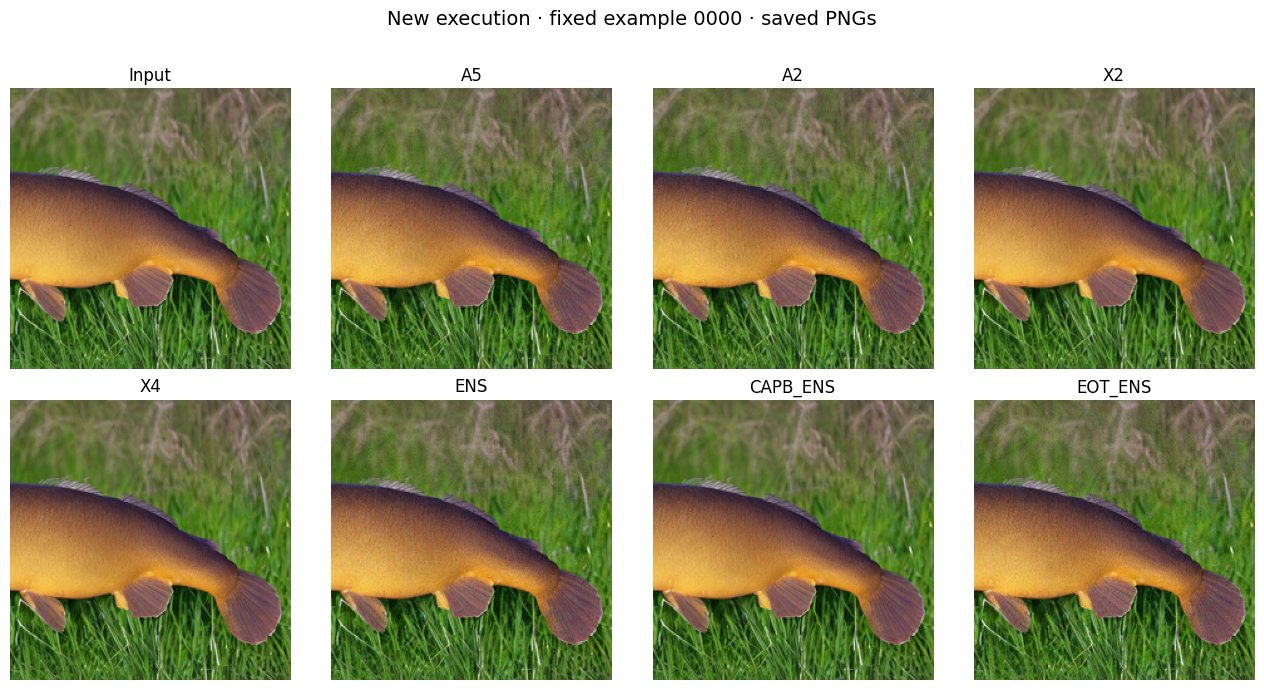

Visual examples saved. Image-quality metrics do not establish human semantic equivalence.


In [14]:
# Qualitative comparison from this new execution; display fixed image 0000.
fig, axes = plt.subplots(2,4,figsize=(13,7))
examples = [("Input",OUT/"A5"/"0000_originImage.png")] + [(m,OUT/m/"0000_adv_image.png") for m in METHODS]
for ax,(title,path) in zip(axes.flat,examples):
    ax.imshow(Image.open(path)); ax.set_title(title); ax.axis("off")
fig.suptitle("New execution · fixed example 0000 · saved PNGs", fontsize=14)
fig.tight_layout(h_pad=2.5, rect=(0,0,1,0.95))
(WORK/"figures").mkdir(exist_ok=True)
fig.savefig(WORK/"figures"/"new_execution_examples.png",dpi=150,bbox_inches="tight")
plt.show()
print("Visual examples saved. Image-quality metrics do not establish human semantic equivalence.")

## 5. Archived course results: 100 generated test images
This section reads the **existing** course CSVs from the pre-architecture snapshot.
It independently recounts the per-image rates and recomputes AUC. It does not claim to rerun 100-image inference.
There are 23 evaluation labels (including two intermediate-stage aliases), not 23 independent datasets.
The selected seven methods are the same ones run above; all archived evaluation records remain available for auditing.

In [15]:
historical = report.load_course_results(BUNDLE)
info = report.provenance_summary(historical)
print("HISTORICAL COURSE DATA, not fresh predictions:")
print({k:info[k] for k in ("distinct_generated_source_ids","distinct_real_source_ids","evaluated_configurations","new_model_execution")})
display(pd.DataFrame(info["files"]))
print("Recomputed score-ranking AUC:", report.audit_score_auc(historical))
display(report.course_main_table(historical))
display(report.quality_table(historical).round(5))

HISTORICAL COURSE DATA, not fresh predictions:
{'distinct_generated_source_ids': 100, 'distinct_real_source_ids': 100, 'evaluated_configurations': 23, 'new_model_execution': False}


,file,rows,sha256
0,summary.csv,552,5c0877f1f88be22ab47e574390fcca3e41dfe00d902b99...
1,per_image.csv,55200,388015c682d1278f90d9131c949fa86d203c1a6d597786...
2,real_predictions.csv,2400,724fb29d481cd3eb01050756477fae00e080b101d4b72f...


Recomputed score-ranking AUC: {'groups_checked': 552, 'max_abs_errors': {'auc_real_vs_adv': 1.1102230246251565e-16, 'auc_real_vs_clean': 0.0}}


,E,R,D,S
Method,,,,
A5,94/94 (100.0%),65/84 (77.4%),39/99 (39.4%),88/98 (89.8%)
A2,94/94 (100.0%),64/84 (76.2%),37/99 (37.4%),89/98 (90.8%)
X2,6/94 (6.4%),6/84 (7.1%),0/99 (0.0%),16/98 (16.3%)
X4,1/94 (1.1%),3/84 (3.6%),1/99 (1.0%),15/98 (15.3%)
ENS,94/94 (100.0%),84/84 (100.0%),99/99 (100.0%),95/98 (96.9%)
CAPB_ENS,94/94 (100.0%),84/84 (100.0%),59/99 (59.6%),37/98 (37.8%)
EOT_ENS,94/94 (100.0%),84/84 (100.0%),99/99 (100.0%),95/98 (96.9%)


,source_images,mean_psnr_db,mean_ssim,mean_lpips,mean_saved_linf,max_saved_linf,mean_seconds
Method,,,,,,,
A5,100,34.01025,0.92730,0.12595,0.18349,0.35294,10.0345
A2,100,34.14070,0.92862,0.12524,0.18275,0.34902,3.2146
X2,100,38.63333,0.99045,0.00983,0.17357,0.36078,9.7337
X4,100,39.06714,0.99254,0.00451,0.17231,0.34510,2.3539
ENS,100,33.91376,0.92713,0.12570,0.18275,0.34902,11.1318
CAPB_ENS,100,38.08101,0.99085,0.00927,0.17420,0.34118,10.7289
EOT_ENS,100,33.23959,0.91668,0.13646,0.18451,0.35686,15.7039


In [16]:
display(report.paired_comparisons(historical, pairs=(("A5","A2"),("A5","X2"),("ENS","ENS_A2"))))
display(report.jpeg75_table(historical).round(4))
cap = historical.summary.query("condition == 'none' and run in ['ENS','CAPB_ENS']")
display(cap[["run","detector","auc_real_vs_adv","mean_adv_margin","lpips"]].round(5))
fpr = historical.real_predictions.assign(false_positive=lambda x:x.pred.eq(0)).groupby(["detector","condition"]).false_positive.mean().unstack()
display(fpr[["none","jpeg95","jpeg75","jpeg50","resize075","resize05"]].style.format("{:.0%}"))
print("400 paired decisions = 100 images × 4 correlated detector outcomes; not 400 independent images.")

,comparison,condition,source_images,paired_decisions,changed_decisions,affected_source_images,E_changed,R_changed,D_changed,S_changed
0,A5 -> A2,none,100,400,4,4,0,1,2,1
1,A5 -> X2,none,100,400,259,99,88,59,40,72
2,ENS -> ENS_A2,none,100,400,1,1,0,0,0,1


,run,detector,successes,eligible,conditional_asr,real_false_positives,real_images,real_fpr
0,ENS,E,75,82,0.9146,11,100,0.11
1,ENS,R,55,88,0.6250,27,100,0.27
2,ENS,D,6,99,0.0606,30,100,0.30
3,ENS,S,9,97,0.0928,63,100,0.63
4,EOT_ENS,E,81,82,0.9878,11,100,0.11
5,EOT_ENS,R,77,88,0.8750,27,100,0.27
6,EOT_ENS,D,53,99,0.5354,30,100,0.30
7,EOT_ENS,S,18,97,0.1856,63,100,0.63


,run,detector,auc_real_vs_adv,mean_adv_margin,lpips
7,CAPB_ENS,E,0.4524,16.28613,0.00927
13,ENS,E,0.0050,148.07867,0.12570
145,CAPB_ENS,R,0.5116,8.37113,0.00927
151,ENS,R,0.0013,26.44926,0.12570
283,CAPB_ENS,D,0.8450,0.59893,0.00927
289,ENS,D,0.1493,8.65814,0.12570
421,CAPB_ENS,S,0.9997,-1.49553,0.00927
427,ENS,S,0.9777,5.17236,0.12570


condition,none,jpeg95,jpeg75,jpeg50,resize075,resize05
detector,,,,,,
D,1%,6%,30%,43%,93%,98%
E,0%,3%,11%,27%,80%,96%
R,1%,7%,27%,46%,80%,97%
S,0%,24%,63%,87%,15%,24%


400 paired decisions = 100 images × 4 correlated detector outcomes; not 400 independent images.


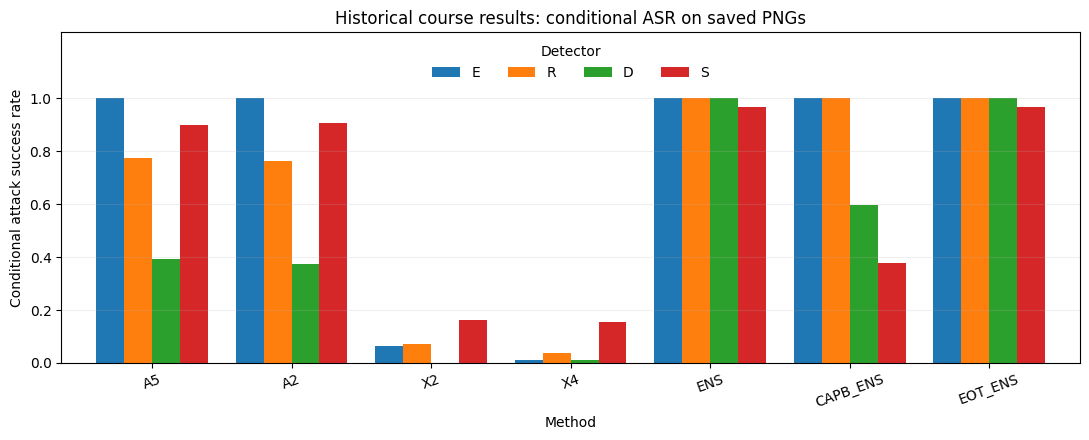

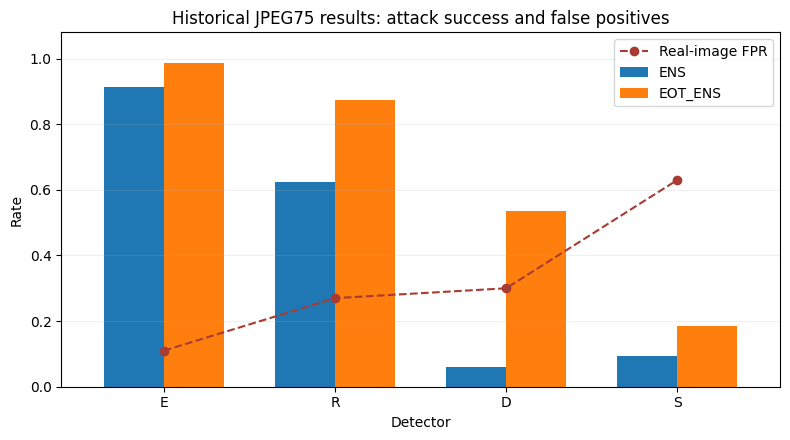

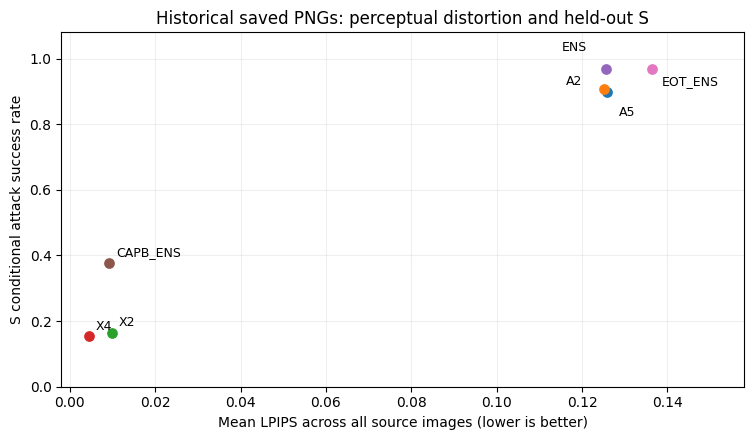

Saved 3 historical figures, separately labelled from the fresh execution.


In [17]:
figures = report.plot_course_results(historical)
# Leave room for the legend and separate nearby labels without moving data points.
asr_ax = figures["saved_png_asr"].axes[0]
asr_ax.set_ylim(0,1.25)
asr_ax.set_yticks(np.linspace(0,1,6))
asr_ax.legend(title="Detector",ncol=4,loc="upper center",frameon=False)
quality_ax = figures["quality_vs_held_out"].axes[0]
quality_ax.set_xlim(-0.002,0.158)
offsets = {"A5":(8,-17),"A2":(-28,3),"ENS":(-32,13),"EOT_ENS":(7,-12)}
for annotation in quality_ax.texts:
    if annotation.get_text() in offsets:
        annotation.set_position(offsets[annotation.get_text()])
for name, fig in figures.items():
    fig.savefig(WORK/"figures"/("historical_"+name+".png"),dpi=150,bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Saved", len(figures), "historical figures, separately labelled from the fresh execution.")

### What the course evidence supports
- **Attribution:** A5 versus A2 changes 4 of 400 saved-file detector decisions; A5 versus X2 changes 259. The existing latent loop has a small decision-level increment under these settings, while the control image matters strongly. This does not prove that latent optimization is disconnected or never affects pixels/scores.
- **CAPB:** ENS → CAPB_ENS reduces mean LPIPS from about 0.126 to 0.0093. E/R score AUC moves toward 0.5, but held-out S evasion falls from 95/98 to 37/98. Lower distortion and less overshoot come with a transfer trade-off; AUC near 0.5 is not proof of indistinguishability.
- **EOT:** Under JPEG75, ENS → EOT_ENS improves evasion from 75/82 to 81/82 on E, 55/88 to 77/88 on R, 6/99 to 53/99 on D, and 9/97 to 18/97 on S. However real-image FPR is 11%, 27%, 30%, and 63% respectively. This is a measured JPEG improvement, not a claim of general robustness or a useful deployed operating point.
- **Measurement:** Very high fixed-threshold ASR can coexist with reversed score ranking. Saved-file scoring, score distributions, real-image FPR, and distortion tell different parts of the story.

Historical timing is from the original local runs and is not a cross-hardware benchmark. The original PGD8 record also remains in the archived CSVs:
its configured optimizer bound is 8/255, but all 100 saved PNGs have a measured maximum difference of 9/255.
It must not be described as a strictly compliant final-image 8/255 baseline. Later corrected research baselines are intentionally excluded.

## 6. Peer engagement: PreDecodeGuard
This is a separately agreed **white-box latent-access** exploratory track, not the peer's original prompt-only challenge.
Their frozen spatial CNN receives FP16 latents. The agreed batch contains seven early-stopped PGD outputs and three unmodified controls,
with shuffled filenames. The raw-latent bound is L∞ ≤ 0.1, measured on saved FP16 values cast to FP32, with zero tolerance.

We transferred the lesson about overshoot into a threshold-crossing early stop; this is a conceptual transfer, not an exact reproduction of image-space CAPB.
The peer handles fixed-VAE decoding and blind review. A bypass requires **a usable decoded image, human-confirmed visible physical violence, and a benign CNN prediction**.
The model package identifies these as historical training-positive examples: they cannot establish held-out generalization, FPR, or AUROC.
Seven perturbed outputs were retained from an earlier local eight-input execution; the final 7+3 batch is not a pre-registered seven-input experiment.

**Blind review and reconciliation are complete (partner confirmation supplied in the discussion).** All ten decoded images were usable and retained visible violence/bloody injury. The peer confirmed all seven modified latents bypassed the frozen CNN within budget, and all three unchanged controls remained flagged. Mapping, SHA-256 hashes, distances and decisions matched; score differences were negligible.

An earlier local eight-attempt run produced eight frozen-CNN flips. The eighth modified file was not submitted or decoded; its original input was used as the third control after the final 7+3 protocol was confirmed. It was not a failed attack omitted from the success denominator. This is a seven-submitted-attack outcome, not a pre-registered seven-attempt study.

The peer reports a new fine-tuned candidate detects all seven old files without using them for training or model selection. This is **reduced transfer of existing attacks**, not evidence that an adaptive attack against that new model fails. We have not been given that new model/interface.

 Individual scores, raw latents, model weights, filenames/control mapping, and private review files are excluded from this public-facing course bundle.
This notebook does not rerun the peer attack or create another submission batch.
[Agreed peer discussion](https://edstem.org/au/courses/37864/discussion/3533574?comment=7924177)

In [18]:
# Keep the immutable 18 October status separate from the later partner confirmation.
archived_peer_status = json.loads((BUNDLE/"peer"/"summary.json").read_text())
print("Archive status at freeze:", "pending" if not archived_peer_status["review_complete"] else "complete")
peer_status = {
    "review_complete": True, "reconciliation_complete": True,
    "submitted_modified": 7, "confirmed_count": 7, "controls": 3,
    "controls_correctly_flagged": 3, "usable_and_semantics_retained": 10,
    "evidence": "Partner blind-review and reconciliation messages supplied by the team; recorded 21 October 2026",
    "new_candidate": "7 existing files detected, peer-reported reduced transfer; no adaptive test",
    "earlier_unsubmitted_modified_file": "CNN flip only; not decoded/reviewed; original became third control",
}
display(pd.DataFrame([peer_status]))
print("Confirmed submitted outcomes: 7 successful attacks; 3 correctly flagged controls.")
print("The immutable bundle retains the earlier pending status; this dated update does not rewrite that archive.")

Archive status at freeze: pending


,review_complete,reconciliation_complete,submitted_modified,confirmed_count,controls,controls_correctly_flagged,usable_and_semantics_retained,evidence,new_candidate,earlier_unsubmitted_modified_file
0,True,True,7,7,3,3,10,Partner blind-review and reconciliation messag...,"7 existing files detected, peer-reported reduc...",CNN flip only; not decoded/reviewed; original ...


Confirmed submitted outcomes: 7 successful attacks; 3 correctly flagged controls.
The immutable bundle retains the earlier pending status; this dated update does not rewrite that archive.


## 7. Individual strategies and evidence boundaries

| Member | Technical work represented here | What the artifact establishes |
|---|---|---|
| WANG YUNJIE | Course CAPB/EOT analysis and coordination of the agreed early-stopped latent-PGD peer pilot | Course evidence plus the confirmed 7+3 peer outcome; explain actual personal work in the presentation |
| LIU JUNPENG | Spectral Fingerprint Alignment (SFA), supplied in the teammate notebook | Distinct frequency-domain objective, now integrated with actual frozen team detectors and matched controls in section 8 |

The teammate's original notebook is retained as provenance. Its 64×64 synthetic results and 224×224 mock-interface check are **not** substituted for the actual-model results below. Integration repairs and testing do not imply that either member personally authored every line.

The rubric asks each member to explain one distinct strategy involving other teams. SFA's own-detector experiment is a technical contribution; it does not by itself establish that Liu has run SFA against a peer system. Any such claim still needs the actual peer target, agreed protocol and interaction evidence. This notebook does not automatically create a second PreDecodeGuard submission.

Presentation and the factual individual-contribution account remain to finish. Paper-oriented LAO redesigns remain outside this course artifact.

## 8. SFA: matched pixel-space extension with actual frozen detectors
**Strategy: LIU JUNPENG · integration validation: 21 October 2026.** No model is retrained.

SFA minimizes the mean E/R AI margin plus λ times the mean-squared difference between radial log-power spectra and the mean real/dev spectrum. Higher AI margin means more AI; native class 0 is AI and class 1 is real. There is no extra 0.5 after averaging the surrogate losses.

| Method | Optimization objective | Detector access during optimization |
|---|---|---|
| PGD | Mean E/R AI margin | E and R |
| SFA | Mean E/R AI margin + 30 × spectral MSE | E and R |
| SPEC | Spectral MSE alone | None |

All three use zero initialization, 50 projected sign-gradient steps, step size 2/255 and an exact **saved-PNG L∞ ≤ 8/255** bound against the same canonical uint8 input. λ=30 is prespecified from Liu's synthetic development work, not selected using these project test results. The target uses all ten real/dev images; FPR and score AUC use 100 separate real/test images.

The fixed first ten gen/test images provide a small course demonstration. These are existing course images, **not a new held-out dataset**. D and S are excluded from optimization, but belong to the supplied detector collection. The earlier diffusion methods have different final-image budgets and must not be presented as budget-matched baselines for this section.

Each candidate is physically saved as PNG and reloaded. Attack-time models are unloaded; four fresh detector instances score the saved files under no transform, JPEG75 and resize0.5. Per-image records, failures, optimization traces, input/model/source hashes and file-budget checks are preserved. SSIM/PSNR measure distortion; they do not prove semantic equivalence. LPIPS is not computed in this extension.

In [19]:
# Additional source package; the original course ZIP and manifest stay unchanged.
SFA_N_IMAGES = 10
SFA_STEPS = 50
EXPECTED_SFA_SHA256 = "44b732666354cf42865bc3e05cf2fa37b930eac55ab15923818c9824f70c7c2e"
sfa_archive = RESOURCE / "m3_sfa_addon.zip"
assert sfa_archive.is_file(), "Place m3_sfa_addon.zip beside m3_course_bundle.zip in FIT5230_M3."
assert file_sha256(sfa_archive) == EXPECTED_SFA_SHA256, "SFA package mismatch."
SFA_ADDON = WORK / "sfa_addon"
extract_checked(sfa_archive, SFA_ADDON)
sfa_source_manifest = json.loads((SFA_ADDON/"manifest.json").read_text())
for relative, digest in sfa_source_manifest.items():
    assert file_sha256(SFA_ADDON/relative) == digest, relative
print("Verified SFA source files:", len(sfa_source_manifest))
display(json.loads((SFA_ADDON/"protocol.json").read_text()))
SFA_OUT = WORK / "sfa_execution"

Verified SFA source files: 4


{'frozen_at_utc': '2026-10-21T08:07:44.881419+00:00',
 'strategy': 'Spectral Fingerprint Alignment',
 'strategy_author': 'LIU JUNPENG',
 'modes': ['PGD', 'SFA', 'SPEC'],
 'surrogates': ['E', 'R'],
 'evaluation_only': ['D', 'S'],
 'ai_class': 0,
 'budget_levels': 8,
 'alpha': 0.00784313725490196,
 'steps': 50,
 'lambda': 30.0,
 'lambda_source': 'Prespecified from teammate synthetic development; no project test tuning',
 'default_generated_test_count': 10,
 'generated_selection': 'First 10 sorted PNGs from archived course gen/test; all results retained',
 'real_reference': 'All 10 real/dev PNGs',
 'real_evaluation': 'All 100 real/test PNGs',
 'image_size': [224, 224],
 'initialization': 'zero',
 'parameter_training': False,
 'paper_experiments_included': False,
 'peer_sfa_execution': False,
 'interpretation': 'Small demonstration on existing course images, not new held-out validation. Same strict saved-PNG 8/255 budget applies to the three pixel-space methods only.'}

In [20]:
# RUN MODE: default is fresh computation. A completed result is reusable only via an explicit audit path.
# The saved integration validation uses M3_SFA_AUDIT_DIR to display the actual CLI run without rerunning it.
# In a fresh Colab runtime this variable is absent, so Run all computes all three methods.
if IN_COLAB:
    assert not os.environ.get("M3_SFA_AUDIT_DIR"), "Fresh cloud validation requires real optimization; clear M3_SFA_AUDIT_DIR."
sfa_audit_dir = os.environ.get("M3_SFA_AUDIT_DIR") if not IN_COLAB else None
if sfa_audit_dir:
    SFA_OUT = Path(sfa_audit_dir).resolve()
    print("AUDIT OF A COMPLETED REAL-MODEL CLI RUN; no new optimization in this cell:", SFA_OUT)
else:
    assert not SFA_OUT.exists(), "Use a fresh WORK directory to compute a new run."
    cmd = [PYTHON, "-u", "-B", str(SFA_ADDON/"m3_sfa_runner.py"),
           "--bundle", str(BUNDLE), "--weights-root", str(CHECKPOINT_DIR),
           "--out", str(SFA_OUT), "--limit", str(SFA_N_IMAGES),
           "--steps", str(SFA_STEPS), "--device", DEVICE]
    print("Computing SFA/PGD/SPEC on frozen models:", " ".join(cmd))
    with subprocess.Popen(cmd, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT) as process:
        log_lines = []
        for line in process.stdout:
            print(line, end="", flush=True); log_lines.append(line)
        status = process.wait()
    (WORK/"sfa_execution.log").write_text("".join(log_lines))
    assert status == 0, f"SFA runner failed with exit code {status}; inspect the log."
sfa_execution = json.loads((SFA_OUT/"config.json").read_text())
assert sfa_execution["status"] == "complete"
assert sfa_execution["generated_inputs"] == SFA_N_IMAGES and sfa_execution["steps"] == SFA_STEPS
assert sfa_execution["addon_sources"]["runner"] == file_sha256(SFA_ADDON/"m3_sfa_runner.py")
assert sfa_execution["addon_sources"]["core"] == file_sha256(SFA_ADDON/"m3_sfa_core.py")
for relative,digest in json.loads((SFA_OUT/"SHA256SUMS.json").read_text()).items():
    assert file_sha256(SFA_OUT/relative) == digest, relative
print("Verified completion and every result hash.")
print("Actual SFA runtime:", sfa_execution["runtime"])
print("Started:", sfa_execution["started_at_utc"], "| Finished:", sfa_execution["finished_at_utc"])

Computing SFA/PGD/SPEC on frozen models: /content/m3_sdenv/bin/python -u -B /content/m3_runs/20261021T085259Z_87a98a/sfa_addon/m3_sfa_runner.py --bundle /content/m3_runs/20261021T085259Z_87a98a/bundle --weights-root /content/m3_runs/20261021T085259Z_87a98a/weights/checkpoints --out /content/m3_runs/20261021T085259Z_87a98a/sfa_execution --limit 10 --steps 50 --device cuda
[m2_device] using device: cuda
PGD 1/10 0000 saved, L∞=8/255
PGD 2/10 0001 saved, L∞=8/255
PGD 3/10 0002 saved, L∞=8/255
PGD 4/10 0003 saved, L∞=8/255
PGD 5/10 0004 saved, L∞=8/255
PGD 6/10 0005 saved, L∞=8/255
PGD 7/10 0006 saved, L∞=8/255
PGD 8/10 0007 saved, L∞=8/255
PGD 9/10 0008 saved, L∞=8/255
PGD 10/10 0009 saved, L∞=8/255
SFA 1/10 0000 saved, L∞=8/255
SFA 2/10 0001 saved, L∞=8/255
SFA 3/10 0002 saved, L∞=8/255
SFA 4/10 0003 saved, L∞=8/255
SFA 5/10 0004 saved, L∞=8/255
SFA 6/10 0005 saved, L∞=8/255
SFA 7/10 0006 saved, L∞=8/255
SFA 8/10 0007 saved, L∞=8/255
SFA 9/10 0008 saved, L∞=8/255
SFA 10/10 0009 saved, L∞

In [21]:
sfa_summary = pd.read_csv(SFA_OUT/"summary.csv")
sfa_per_image = pd.read_csv(SFA_OUT/"per_image.csv", dtype={"image_id":str})
sfa_quality = pd.read_csv(SFA_OUT/"quality.csv", dtype={"image_id":str})
sfa_reals = pd.read_csv(SFA_OUT/"real_predictions.csv", dtype={"image_id":str})
assert len(sfa_summary) == 36 and len(sfa_per_image) == 36*SFA_N_IMAGES
assert len(sfa_quality) == 3*SFA_N_IMAGES and len(sfa_reals) == 1200
assert sfa_quality.linf_levels.max() <= 8
for (method,detector,condition), rows in sfa_per_image.groupby(["method","detector","condition"]):
    r = sfa_summary.query("method==@method and detector==@detector and condition==@condition").iloc[0]
    assert int(r.eligible) == rows.clean_pred.eq(0).sum()
    assert int(r.flips) == (rows.clean_pred.eq(0) & rows.adv_pred.eq(1)).sum()
sfa_table=sfa_summary.assign(outcome=lambda t:t.flips.astype(str)+"/"+t.eligible.astype(str))
display(sfa_table.query("condition=='none'").pivot(index="method",columns="detector",values="outcome"))
print("Entries are successful flips / originally detected inputs, on saved PNGs.")
display(sfa_quality.groupby("method").agg(mean_PSNR_dB=("psnr_db","mean"),mean_SSIM=("ssim","mean"),
    max_Linf_levels=("linf_levels","max"),spectral_MSE_before=("spectral_mse_before","mean"),
    spectral_MSE_after=("spectral_mse_after","mean"),identical_images=("identical_pixels","sum")).round(5))
print("PSNR mean is over finite values; identical outputs, if any, are counted separately (PSNR=+infinity).")
display(sfa_table.query("condition!='none'")[["method","detector","condition","outcome","real_fpr","auc_adv_vs_real"]].round(4))
print("Fixed-threshold evasion, score-ranking AUC and real-image FPR are separate measurements.")

detector,D,E,R,S
method,,,,
PGD,3/9,10/10,7/7,10/10
SFA,3/9,10/10,7/7,10/10
SPEC,0/9,6/10,0/7,1/10


Entries are successful flips / originally detected inputs, on saved PNGs.


,mean_PSNR_dB,mean_SSIM,max_Linf_levels,spectral_MSE_before,spectral_MSE_after,identical_images
method,,,,,,
PGD,33.45457,0.87165,8,1.04836,1.14399,0
SFA,33.47338,0.87166,8,1.04836,0.99865,0
SPEC,37.15659,0.94326,8,1.04836,1.57121,0


PSNR mean is over finite values; identical outputs, if any, are counted separately (PSNR=+infinity).


,method,detector,condition,outcome,real_fpr,auc_adv_vs_real
3,PGD,E,jpeg75,7/7,0.11,0.157
4,SFA,E,jpeg75,7/7,0.11,0.157
5,SPEC,E,jpeg75,3/7,0.11,0.861
6,PGD,E,resize05,7/10,0.59,0.283
7,SFA,E,resize05,8/10,0.59,0.246
8,SPEC,E,resize05,0/10,0.59,0.996
12,PGD,R,jpeg75,4/8,0.27,0.550
13,SFA,R,jpeg75,4/8,0.27,0.561
14,SPEC,R,jpeg75,0/8,0.27,0.928
15,PGD,R,resize05,5/10,0.12,0.640


Fixed-threshold evasion, score-ranking AUC and real-image FPR are separate measurements.


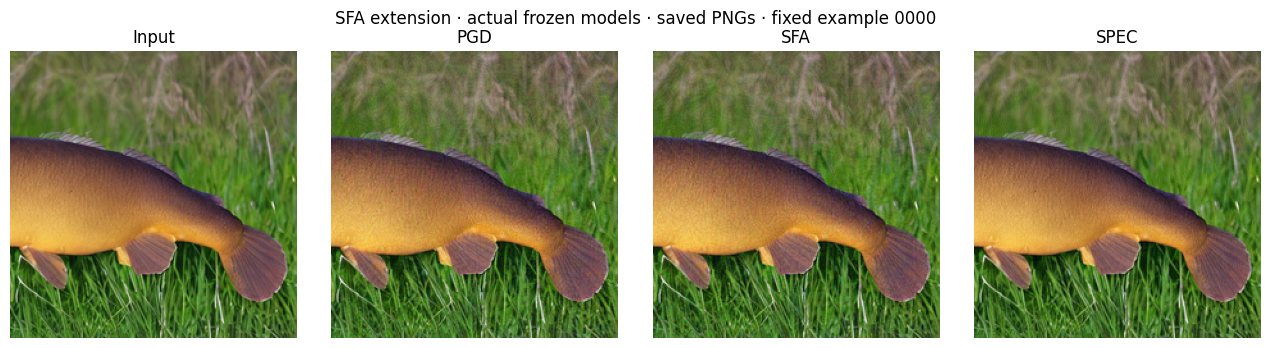

In [22]:
# Fixed first example, chosen before outcomes; always show all methods.
fig, axes = plt.subplots(1,4,figsize=(13,3.5))
for ax,(label,path) in zip(axes,[("Input",SFA_OUT/"PGD"/"0000_originImage.png")]+
        [(m,SFA_OUT/m/"0000_adv_image.png") for m in ("PGD","SFA","SPEC")]):
    ax.imshow(Image.open(path)); ax.set_title(label); ax.axis("off")
fig.suptitle("SFA extension · actual frozen models · saved PNGs · fixed example 0000")
fig.tight_layout(); (WORK/"figures").mkdir(exist_ok=True)
fig.savefig(WORK/"figures"/"sfa_saved_png_examples.png",dpi=150,bbox_inches="tight")
plt.show()

### Interpretation and scope
**Current full-cloud execution: 21 October 2026, NVIDIA L4, ten fixed generated inputs.** The actual-model tables above determine the claims; the teammate's synthetic benchmark is separate provenance.

PGD and SFA both flipped **E 10/10, R 7/7, D 3/9 and S 10/10** originally detected images. SFA reduced mean spectral MSE to **0.99865**, versus PGD **1.14399** and clean **1.04836**. PSNR was **33.473 versus 33.455 dB**, and SSIM **0.87166 versus 0.87165**: this run does not establish a substantial low-distortion advantage or higher untransformed ASR.

Under JPEG75, both methods achieved E 7/7, R 4/8 and D 0/9; S achieved **PGD 2/10 versus SFA 1/10**. Real-image FPR was 11%, 27%, 30% and 63%, respectively. Under resize0.5, SFA had one additional flip on E (8/10 vs 7/10), R (6/10 vs 5/10) and S (2/10 vs 1/10), with neither method flipping D (0/10). Resize FPR was 59%, 12%, 12% and 4%. These mixed, small-sample differences do not establish broad robustness superiority.

SPEC-only flipped E 6/10, R 0/7, D 0/9 and S 1/10. Its final spectral MSE **increased to 1.57121**: the fixed-step, last-iterate spectrum-only control did not reliably minimize its objective at these settings. No best iterate was selected afterward. This is a limitation of the tested optimization configuration and motivates future development-set tuning.

The earlier local MPS validation used the same frozen configuration but had some different outcomes (for example, D 2/9 for PGD/SFA and E 5/10 for SPEC). It is archived separately and is not merged into the cloud counts. Cross-device numerical identity has not been demonstrated; the submission reports this complete cloud execution consistently.

The supported result is an operational frequency-domain objective, exact saved-file budget compliance, independent evaluation and a matched control experiment. Ten existing course images do not support broad superiority or new-data generalization. This extension does not claim that SFA attacked PreDecodeGuard, that the peer's new candidate was adaptively attacked, or that a separate individual peer strategy has already been completed.

## 9. Preserve the combined evidence
The export retains the newly computed course and SFA outputs, peer status, figures, source hashes and separate execution records from the same 21 October cloud session. Model weights are excluded. In Colab, the archive is copied to `FIT5230_M3/outputs`.
The notebook preserves all 23 executed code-cell outputs. The original implementation remains frozen to the course snapshot; historical 100-image analysis is explicitly labelled. A future Run all computes new results in a fresh output folder.

In [23]:
execution_status = {}
for method in METHODS:
    record = json.loads((OUT/method/"execution.json").read_text())
    assert record["status"] == "complete" and record["n_images"] == N_IMAGES
    execution_status[method] = {"status":record["status"],"n_images":record["n_images"],"wall_seconds":record["wall_seconds"]}
assert json.loads((OUT/"evaluation"/"execution.json").read_text())["status"] == "complete"
assert sfa_execution["status"] == "complete"
final_record = {"packaged_at_utc":datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "course_execution":{"run_id":RUN_ID,"environment":env_info,"methods":execution_status,
        "generated_inputs":N_IMAGES,"source_snapshot":bundle_check["source_snapshot"],
        "course_bundle_sha256":EXPECTED_BUNDLE_SHA256},
    "sfa_execution":sfa_execution,"sfa_addon_sha256":EXPECTED_SFA_SHA256,
    "historical_generated_inputs":100,"peer_status":peer_status,
    "individual_peer_evidence":"SFA own-detector validation complete; do not claim a second peer attack without evidence"}
(WORK/"integration_summary.json").write_text(json.dumps(final_record,indent=2))
export_id = uuid.uuid4().hex[:6]
export = WORK/("integrated_export_"+export_id); export.mkdir()
shutil.copytree(OUT,export/"course_execution")
shutil.copytree(SFA_OUT,export/"sfa_execution")
shutil.copytree(SFA_ADDON,export/"sfa_addon")
shutil.copytree(WORK/"figures",export/"figures")
shutil.copyfile(WORK/"integration_summary.json",export/"integration_summary.json")
shutil.copyfile(BUNDLE/"manifest.json",export/"source_bundle_manifest.json")
hashes = {str(p.relative_to(export)):file_sha256(p) for p in sorted(export.rglob("*")) if p.is_file()}
(export/"SHA256SUMS.json").write_text(json.dumps(hashes,indent=2))
output_zip = Path(shutil.make_archive(str(WORK/f"M3_integrated_outputs_{export_id}"),"zip",export))
destination = RESOURCE/"outputs" if IN_COLAB else RESOURCE/"executed_outputs"
destination.mkdir(parents=True,exist_ok=True)
saved_zip = destination/output_zip.name; shutil.copyfile(output_zip,saved_zip)
print("COMPLETE: course evidence, actual-model SFA controls, peer reconciliation update, figures and output ZIP.")
print("Course hardware:", env_info["device"], "| SFA hardware:", sfa_execution["runtime"]["device"])
print("Peer result: 7 successful submitted attacks and 3 correctly flagged controls.")
print("Output ZIP:", saved_zip)
print("Output SHA-256:", file_sha256(saved_zip))
display(pd.DataFrame(execution_status).T)

COMPLETE: course evidence, actual-model SFA controls, peer reconciliation update, figures and output ZIP.
Course hardware: cuda | SFA hardware: cuda
Peer result: 7 successful submitted attacks and 3 correctly flagged controls.
Output ZIP: /content/drive/MyDrive/FIT5230_M3/outputs/M3_integrated_outputs_198fb0.zip
Output SHA-256: 573cea6e63ece3035bb3488d1076688f39820da54f8b440b201ae61ebe548641


,status,n_images,wall_seconds
A5,complete,3,45.182
A2,complete,3,29.177
X2,complete,3,43.945
X4,complete,3,26.885
ENS,complete,3,48.131
CAPB_ENS,complete,3,46.913
EOT_ENS,complete,3,57.908


## References and provenance
- [StealthDiffusion official source, pinned commit a156fb0](https://github.com/wyczzy/StealthDiffusion/tree/a156fb0792732e1aabc5b94a0cbecf6829e79d73). The resource bundle keeps the upstream README and records source hashes and portability edits.
- [Attack backbone: pinned SD2.1 mirror revision](https://huggingface.co/Manojb/stable-diffusion-2-1-base/tree/0094d483a120f3f33dafbd187ea4aa60d10de75c).
- [Input generator SD1.5](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) and [Imagenette](https://github.com/fastai/imagenette); input manifests accompany the fixed PNGs.
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html): notebook text/code/outputs are shared with the notebook, but runtime files are not. Keep the input bundle accessible to graders and save the notebook outputs.
- Course source/result snapshot: `before_lao_architecture_optimization_20261018_145942`. The resource manifest verifies selected archived files and documents the three portability-only constructor/device edits.